In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})
df.loc[0:5, 'study_hours'] = np.nan   
df.loc[99, 'study_hours'] = 50        
df.loc[98, 'attendance'] = -10   

In [2]:
df

,study_hours,attendance,previous_mark,final_score
0,NaN,70.846293,75.366810,35.178989
1,NaN,80.793547,78.411768,39.481248
2,NaN,81.572855,86.245769,48.605167
3,NaN,76.977227,85.807031,47.329456
4,NaN,83.387143,49.334959,37.044473
...,...,...,...,...
95,2.072970,88.853174,59.606356,37.267830
96,5.592241,76.161426,83.493998,33.777675
97,5.522111,86.537251,74.609493,50.413491
98,5.010227,-10.000000,82.192932,44.045627


In [3]:
print(df.isna().sum())
print(df.describe())

df_clean = df.drop(index=[98, 99]).copy()
df_clean['study_hours'] = df_clean['study_hours'].fillna(df_clean['study_hours'].median())

X = df_clean[['study_hours', 'attendance', 'previous_mark']]
y = df_clean['final_score']
print("Feature matrix shape:", X.shape)

study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64
       study_hours  attendance  previous_mark  final_score
count    94.000000  100.000000     100.000000   100.000000
mean      5.218916   84.267225      70.973444    42.691957
std       5.014751   13.476443      16.264243     6.086797
min      -0.239490  -10.000000      21.380990    29.163251
25%       3.731467   76.829717      60.168347    38.188854
50%       4.812342   85.841072      71.465436    42.763014
75%       5.744365   90.381704      80.566562    46.688328
max      50.000000  112.201692     127.790972    57.171201
Feature matrix shape: (98, 3)


In [4]:
summary = df_clean.agg(['mean', 'median', 'std']).T
print(summary)

                    mean     median        std
study_hours     4.732245   4.698693   1.792777
attendance     85.338288  86.266882   9.560809
previous_mark  70.772521  71.137572  16.367696
final_score    42.640159  42.555703   6.135841


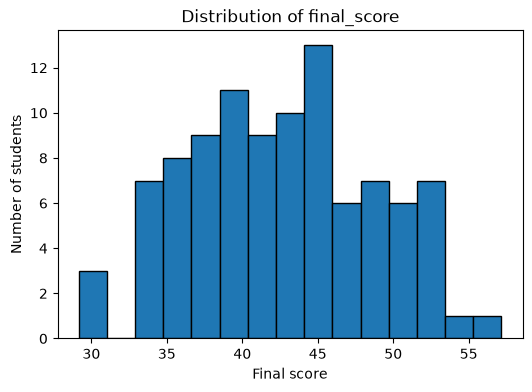

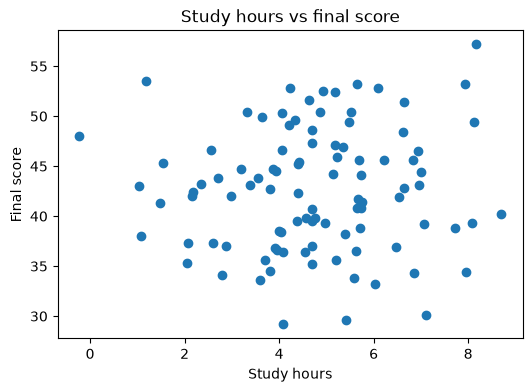

In [5]:
plt.figure(figsize=(6,4))
plt.hist(df_clean['final_score'], bins=15, edgecolor='black')
plt.xlabel('Final score')
plt.ylabel('Number of students')
plt.title('Distribution of final_score')
plt.show()

plt.figure(figsize=(6,4))
plt.scatter(df_clean['study_hours'], df_clean['final_score'])
plt.xlabel('Study hours')
plt.ylabel('Final score')
plt.title('Study hours vs final score')
plt.show()

In [6]:
r = df_clean['study_hours'].corr(df_clean['final_score'])
print("Pearson r =", r)

Pearson r = 0.05003129196131304


In [7]:
x = X.iloc[0].values
w = np.array([0.5, 0.2, 0.4])
b = 5

y_pred = np.dot(w, x) + b
print("x =", x)
print("Predicted score =", y_pred)


x = [ 4.69869274 70.84629258 75.36681041]
Predicted score = 51.66532904846284


In [8]:
for col in ['study_hours', 'previous_mark']:
    df_clean[col + '_scaled'] = (df_clean[col] - df_clean[col].mean()) / df_clean[col].std()

print(df_clean[['study_hours_scaled', 'previous_mark_scaled']].agg(['mean', 'std']))
print(df_clean[['study_hours', 'previous_mark']].agg(['min', 'max']))

      study_hours_scaled  previous_mark_scaled
mean       -1.076237e-17          1.026956e-15
std         1.000000e+00          1.000000e+00
     study_hours  previous_mark
min    -0.239490      21.380990
max     8.704556     127.790972
